# Imports

In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**Giải thích:** Cell này import các thư viện nền tảng phục vụ xử lý và trực quan hóa dữ liệu:
- `pandas`: đọc, xử lý và thao tác dữ liệu dạng bảng (DataFrame).
- `numpy`: hỗ trợ tính toán mảng số học.
- `seaborn`: vẽ các biểu đồ thống kê trực quan (như heatmap, phân phối).
- `matplotlib.pyplot`: tạo và tùy chỉnh các biểu đồ cơ bản.

In [2]:
data1 = pd.read_csv("/kaggle/input/datasets/tnngth/user-data/user1_data-1.csv")
data2 = pd.read_csv("/kaggle/input/datasets/tnngth/user-data/user2_data-1.csv")

**Giải thích:** Cell này đọc hai tập dữ liệu cảm biến từ file CSV vào chương trình:
- `pd.read_csv(...)`: nạp dữ liệu từ đường dẫn file CSV vào hai DataFrame `data1` và `data2`.

# Data Visualiztion

In [3]:
data1.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'st', 'lum'], dtype='object')

In [4]:
data1.shape

(19341, 8)

In [5]:
data2.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum', 'temp', 'humd',
       'pres'],
      dtype='object')

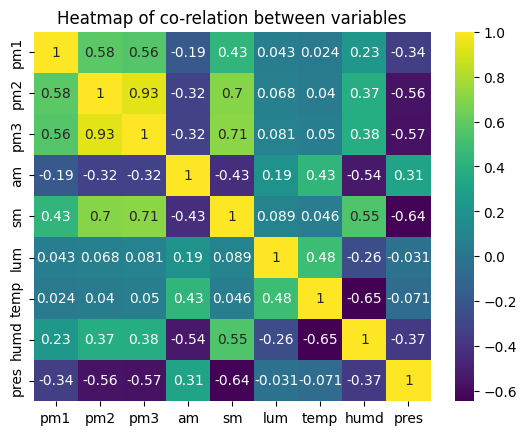

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm numeric_only=True vào hàm .corr()
sns.heatmap(data2.corr(numeric_only=True), annot=True, cmap="viridis")
plt.title("Heatmap of co-relation between variables")
plt.show()

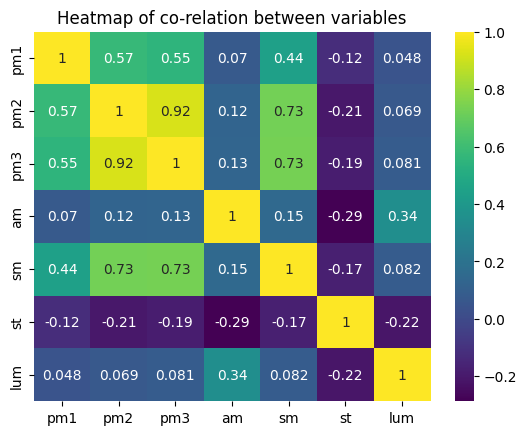

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data1.corr(numeric_only=True),annot=True,cmap='viridis')
plt.title('Heatmap of co-relation between variables')
plt.show()

**Giải thích:** 2 cell trên vẽ biểu đồ nhiệt (heatmap) thể hiện ma trận tương quan giữa các biến số trong `data1` và `data2`:
- `data.corr(numeric_only=True)`: tính hệ số tương quan giữa các cột dạng số.
- `sns.heatmap(..., annot=True, cmap="viridis")`: hiển thị ma trận tương quan kèm giá trị số trên từng ô với bảng màu `viridis`.
- `plt.title(...)` và `plt.show()`: đặt tiêu đề và hiển thị biểu đồ.

In [8]:
data1.tail() 

,ttime,pm1,pm2,pm3,am,sm,st,lum
19336,2023-03-10 08:45:06,1.11,1.11,28.49,3.2,291.0,29.40,384.0
19337,2023-03-10 09:12:06,0.55,1.11,28.49,3.2,292.0,29.32,384.0
19338,2023-03-10 09:39:09,1.11,1.11,28.49,2.4,291.0,29.24,384.0
19339,2023-03-10 10:06:09,0.55,1.11,28.49,1.6,291.0,29.17,384.0
19340,2023-03-10 11:01:05,0.55,1.11,28.49,8.8,292.0,29.06,384.0


# Data Pre-Prosessing

In [9]:
data1['ttime']=pd.to_datetime(data1.ttime, format='%Y-%m-%d %H:%M:%S')
data1.set_index('ttime',inplace=True)
data1['day']=data1.index.day
data1['Month']=data1.index.month
data1['year']=data1.index.year
data1['hour']=data1.index.hour
data1['min']=(data1.index.minute//5)+1
data1.reset_index(inplace=True)
data1=data1.drop('ttime',axis = 1)
data1

,pm1,pm2,pm3,am,sm,st,lum,day,Month,year,hour,min
0,3.63,0.00,0.00,3.2,7813.0,25.65,15001.0,18,7,2022,15,9
1,4.19,0.00,0.00,4.8,7692.0,25.66,13863.0,18,7,2022,15,10
2,4.74,0.00,0.00,4.0,7813.0,25.67,13788.0,18,7,2022,15,11
3,5.30,0.00,0.00,4.8,7813.0,25.68,14383.0,18,7,2022,15,12
4,0.55,5.30,5.30,3.2,7813.0,25.69,14621.0,18,7,2022,16,1
...,...,...,...,...,...,...,...,...,...,...,...,...
19336,1.11,1.11,28.49,3.2,291.0,29.40,384.0,10,3,2023,8,10
19337,0.55,1.11,28.49,3.2,292.0,29.32,384.0,10,3,2023,9,3
19338,1.11,1.11,28.49,2.4,291.0,29.24,384.0,10,3,2023,9,8
19339,0.55,1.11,28.49,1.6,291.0,29.17,384.0,10,3,2023,10,2


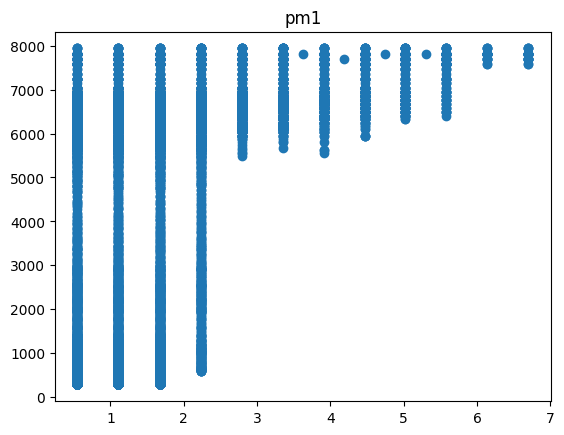

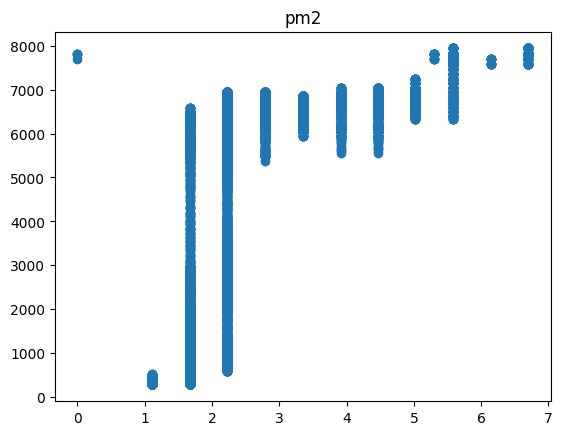

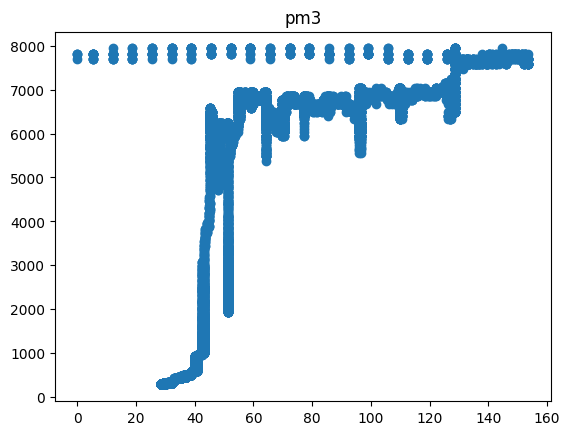

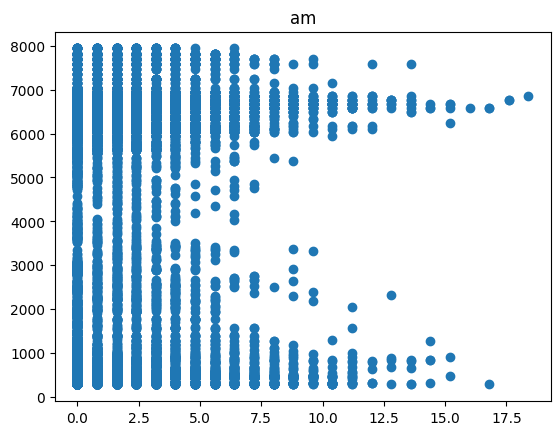

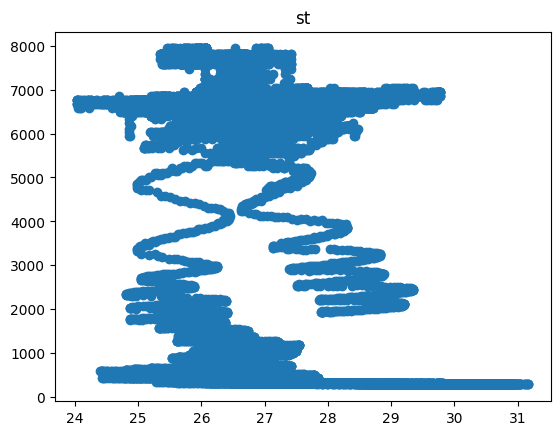

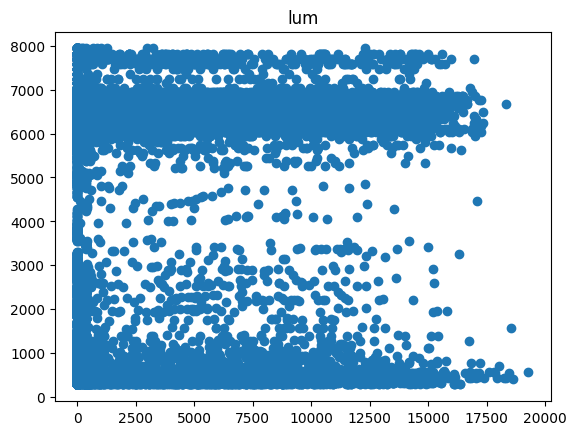

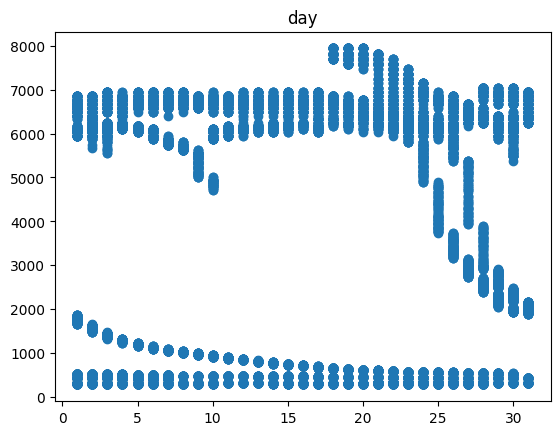

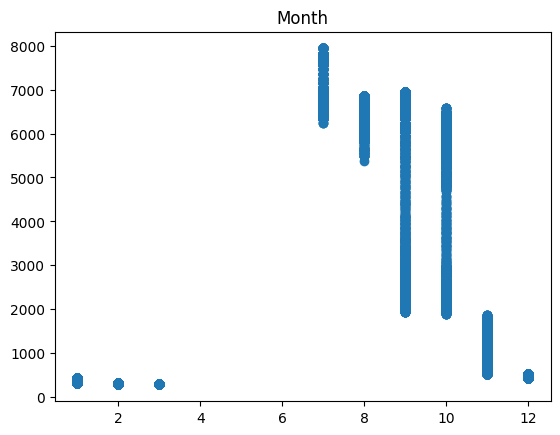

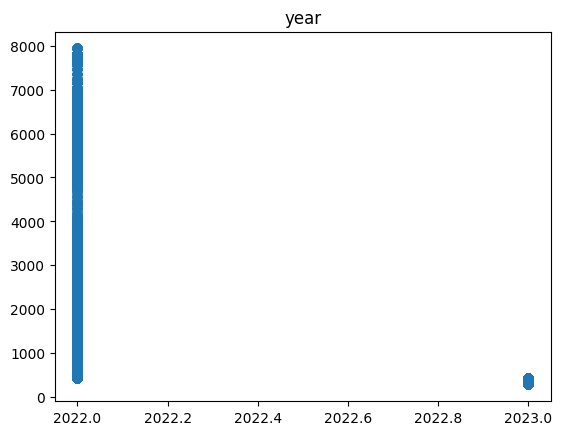

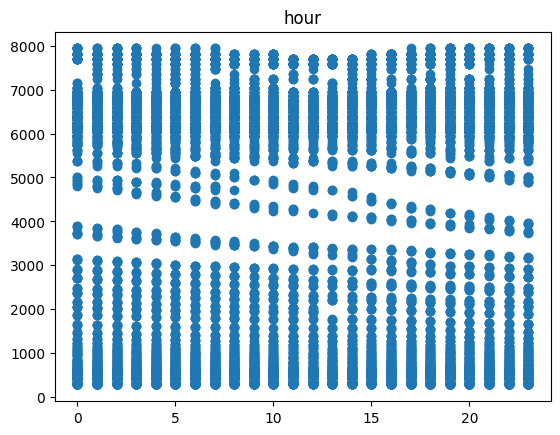

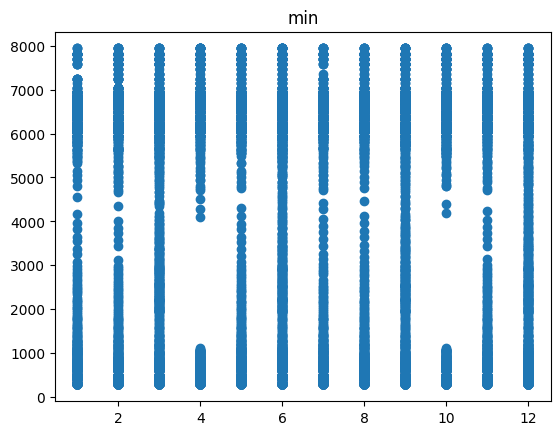

In [10]:
for i in data1.columns.drop('sm'):
  ypoints = data1['sm']
  plt.scatter(data1[i], ypoints)
  plt.title(i)
  plt.show()

In [11]:
data2['ttime']=pd.to_datetime(data2.ttime, format='%Y-%m-%d %H:%M:%S')
data2.set_index('ttime',inplace=True)
data2['day']=data2.index.day
data2['Month']=data2.index.month
data2['year']=data2.index.year
data2['hour']=data2.index.hour
data2['min']=(data2.index.minute//5)+1
data2.reset_index(inplace=True)
data2=data2.drop('ttime', axis = 1)
data2

,pm1,pm2,pm3,am,sm,lum,temp,humd,pres,day,Month,year,hour,min
0,0.83,0.00,0.00,0.0,7463.0,6547.0,23.02,90.57,92849.25,18,7,2022,15,8
1,1.39,0.00,0.00,0.0,7576.0,10249.0,23.47,88.37,92848.31,18,7,2022,15,9
2,1.95,0.00,0.00,0.0,7576.0,12636.0,23.64,85.26,92844.82,18,7,2022,15,10
3,2.51,0.00,0.00,0.0,7463.0,8318.0,23.62,85.93,92834.94,18,7,2022,15,11
4,0.55,2.51,2.51,0.0,7463.0,4149.0,23.82,86.06,92815.25,18,7,2022,15,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20161,0.55,1.11,27.38,3.2,327.0,6352.0,27.04,32.24,93560.72,10,3,2023,8,12
20162,1.11,1.11,27.38,3.2,327.0,7057.0,28.53,28.69,93574.12,10,3,2023,9,6
20163,1.67,1.11,27.38,4.8,327.0,7661.0,30.07,24.39,93571.75,10,3,2023,9,12
20164,0.55,1.67,27.93,4.0,327.0,8386.0,31.55,22.99,93558.36,10,3,2023,10,5


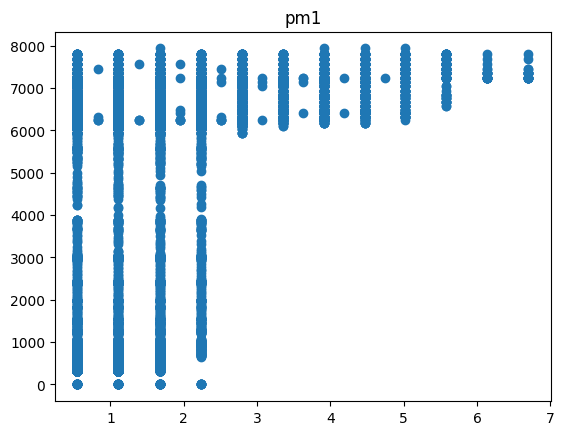

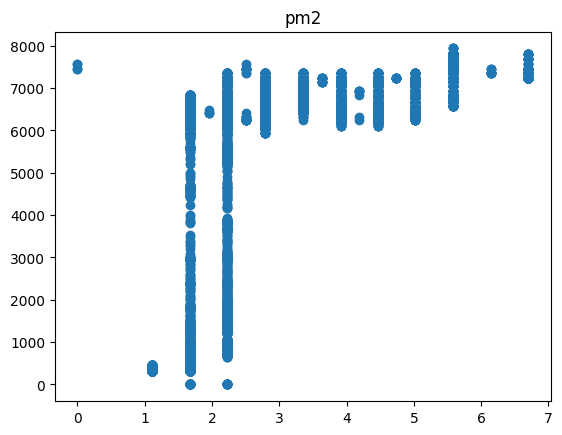

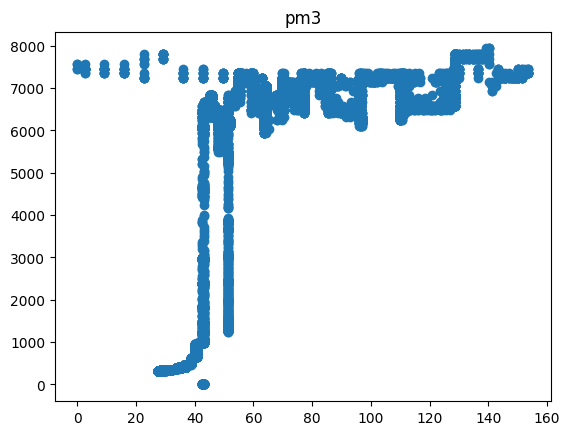

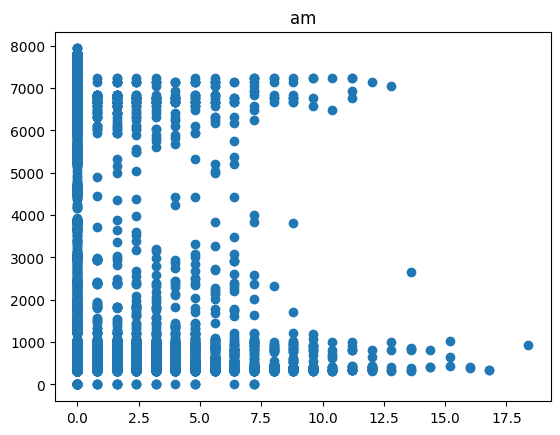

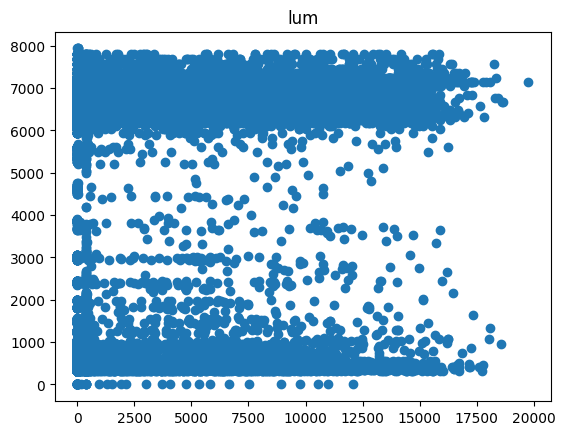

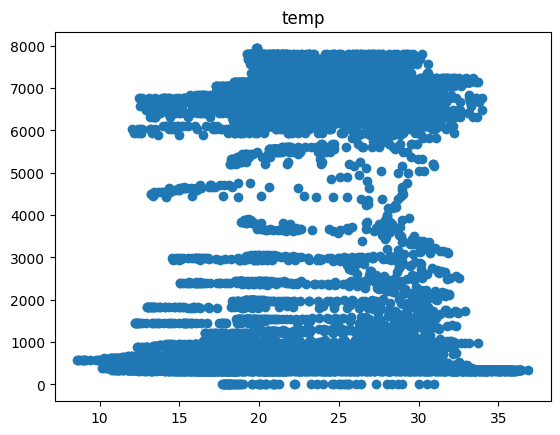

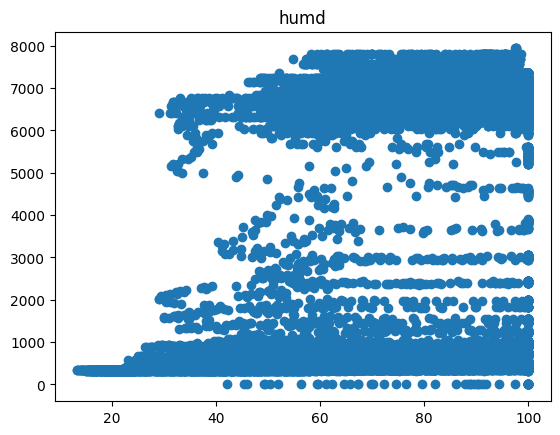

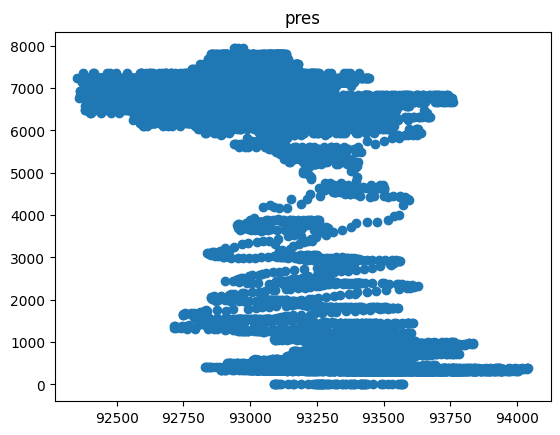

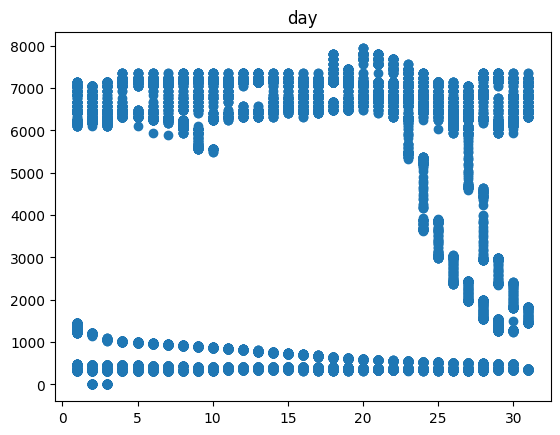

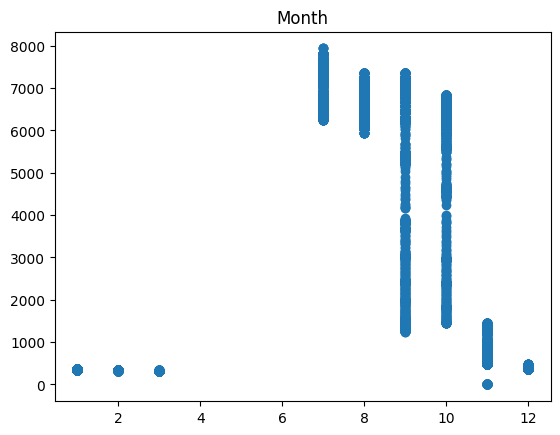

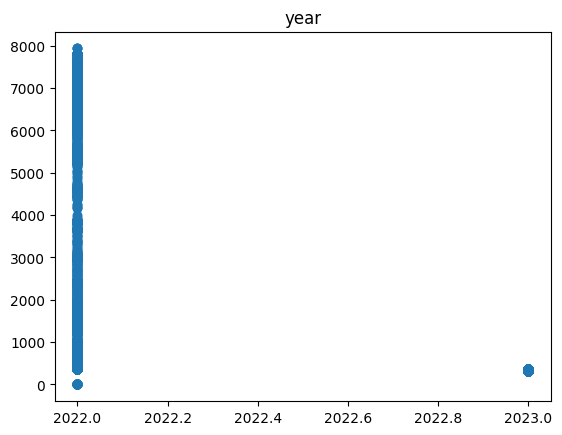

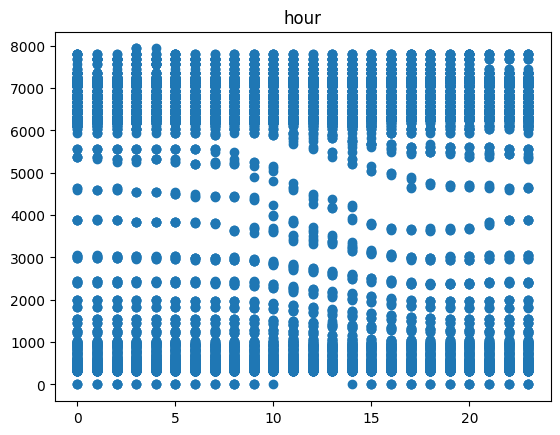

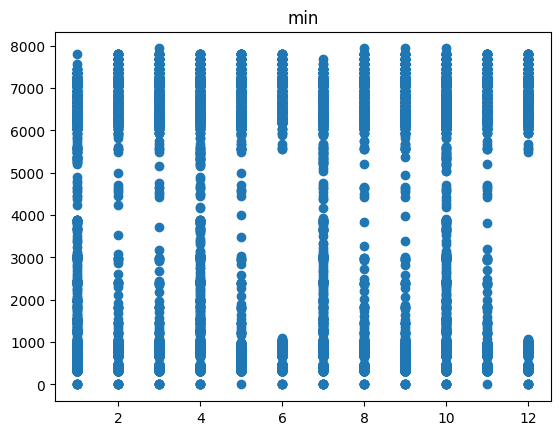

In [12]:
for i in data2.columns.drop('sm'):
  ypoints = data2['sm']
  plt.scatter( data2[i],ypoints)
  plt.title(i)
  plt.show()

**Giải thích:** 4 cell vừa rồi thực hiện tiền xử lý cột thời gian `ttime` của 2 bộ `data` và tách thành các đặc trưng thời gian rồi vẽ các biểu đồ phân tán (scatter plot) giữa các đặc trưng trong 2 bộ `data` với biến mục tiêu `sm` (độ ẩm đất):
- `pd.to_datetime(...)`: chuyển cột `ttime` sang kiểu dữ liệu ngày giờ theo định dạng `%Y-%m-%d %H:%M:%S`.
- `data.set_index('ttime', inplace=True)`: đặt cột `ttime` làm chỉ mục (index) để trích xuất thành phần thời gian.
- Tạo các cột `day`, `Month`, `year`, `hour` từ index thời gian; cột `min` được gom nhóm theo từng khoảng 5 phút (`(minute // 5) + 1`).
- `reset_index(inplace=True)` và `drop('ttime', axis=1)`: khôi phục index mặc định và xóa cột `ttime` gốc, sau đó hiển thị bảng `data1`.
- `for i in data.columns.drop('sm')`: duyệt qua tất cả các cột trừ `sm`.
- `plt.scatter(data1[i], ypoints)`: vẽ biểu đồ phân tán giữa cột `i` và `sm`.
- `plt.title(i)` và `plt.show()`: đặt tên cột làm tiêu đề và hiển thị từng biểu đồ.

# Combine Data

In [17]:
data_comb = data1.merge( data2, on=['day','Month','year','hour','min'], how='outer')
data_comb

,pm1_x,pm2_x,pm3_x,am_x,sm_x,st,lum_x,day,Month,year,...,min,pm1_y,pm2_y,pm3_y,am_y,sm_y,lum_y,temp,humd,pres
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,2023,...,1,0.55,1.11,33.52,0.0,373.0,4.0,17.03,92.56,93737.36
1,0.55,1.67,33.52,0.0,430.0,27.49,1.0,1,1,2023,...,5,1.11,1.11,33.52,0.0,373.0,3.0,16.72,94.43,93718.07
2,1.11,1.67,33.52,0.0,431.0,27.45,1.0,1,1,2023,...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,2023,...,10,1.67,1.11,33.52,0.0,373.0,3.0,16.69,94.27,93694.30
4,0.55,1.11,33.52,0.0,431.0,27.40,1.0,1,1,2023,...,2,0.55,1.67,33.52,0.0,372.0,3.0,16.79,91.79,93670.49
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33033,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,12,2022,...,11,1.67,1.11,33.52,0.0,373.0,4.0,18.15,85.89,93774.81
33034,0.55,1.67,33.52,0.0,431.0,27.59,1.0,31,12,2022,...,3,0.55,1.67,33.52,0.0,373.0,4.0,18.12,85.79,93768.37
33035,1.11,1.67,33.52,0.0,431.0,27.56,1.0,31,12,2022,...,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,12,2022,...,8,1.11,1.67,33.52,0.0,373.0,4.0,17.37,90.32,93748.13


**Giải thích:** Cell này gộp hai tập dữ liệu `data1` và `data2` thành một bảng tổng hợp `data_comb`:
- `data1.merge(data2, on=['day','Month','year','hour','min'], how='outer')`: ghép theo các mốc thời gian chung và dùng `how='outer'` để giữ lại toàn bộ bản ghi từ cả hai bảng.

In [18]:
# data_comb.columns
print('Count of missing values:\n',data_comb.shape[0]-data_comb.count())

Count of missing values:
 pm1_x    13697
pm2_x    13697
pm3_x    13697
am_x     13697
sm_x     13697
st       13697
lum_x    13697
day          0
Month        0
year         0
hour         0
min          0
pm1_y    12872
pm2_y    12872
pm3_y    12872
am_y     12872
sm_y     12872
lum_y    12872
temp     12872
humd     12872
pres     12872
dtype: int64


In [19]:
features = ['pm1', 'pm2', 'pm3', 'am', 'sm', 'lum']
cols_to_drop = []

for feat in features:
    cols = [f'{feat}_x', f'{feat}_y']
    data_comb[feat] = data_comb[cols].mean(axis=1)
    cols_to_drop.extend(cols)

data_comb = data_comb.drop(columns=cols_to_drop)

**Giải thích:** Cell này hợp nhất các cặp cột trùng tên (`_x` từ `data1` và `_y` từ `data2`) sau khi merge:
- Duyệt qua danh sách `features = ['pm1', 'pm2', 'pm3', 'am', 'sm', 'lum']`.
- `data_comb[cols].mean(axis=1)`: tính trung bình theo hàng giữa cột `_x` và `_y` để tạo cột tên gốc (bỏ qua giá trị thiếu nếu một bên không có).
- `cols_to_drop.extend(cols)` và `data_comb.drop(columns=cols_to_drop)`: gom và xóa toàn bộ các cột `_x`, `_y` dư thừa.

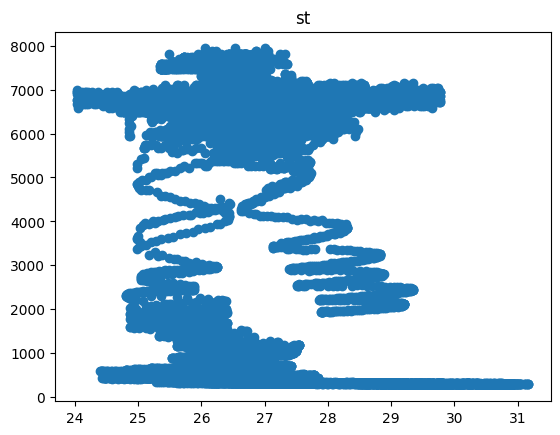

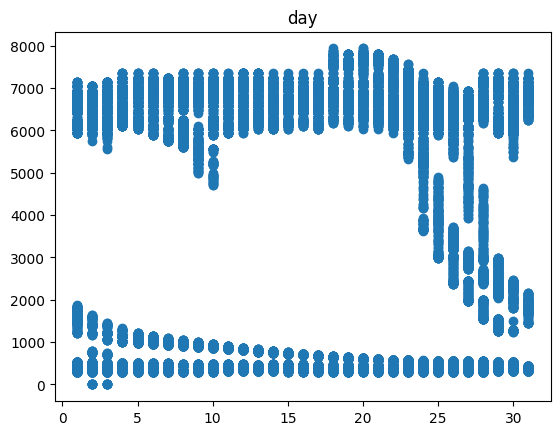

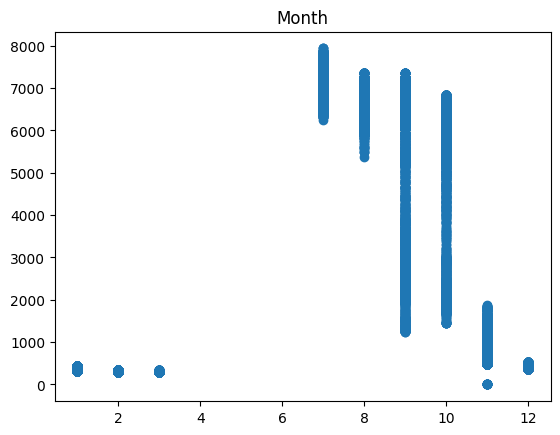

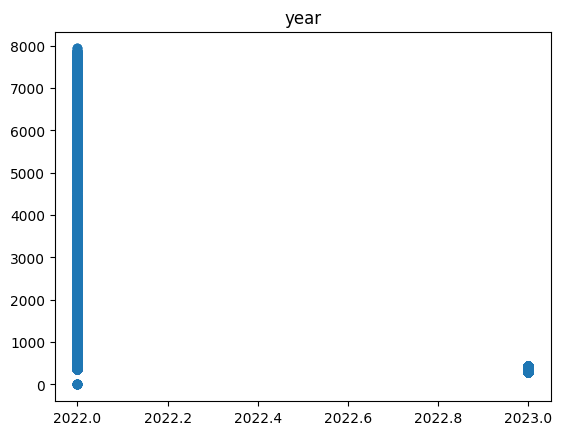

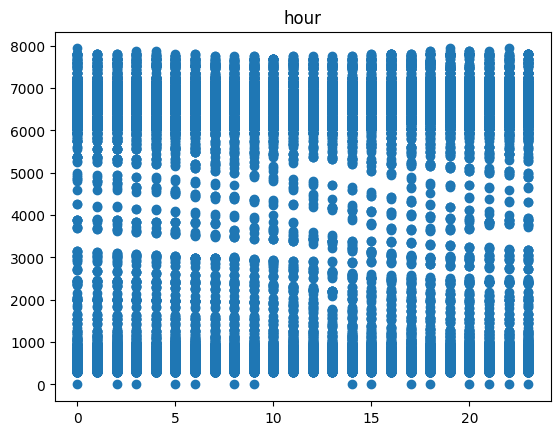

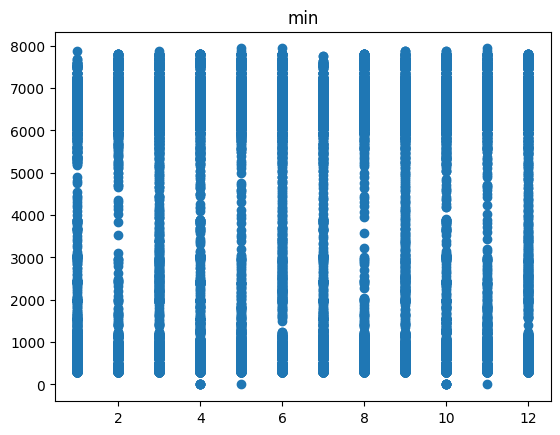

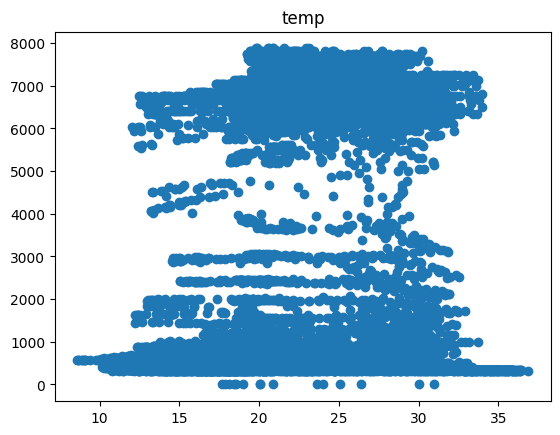

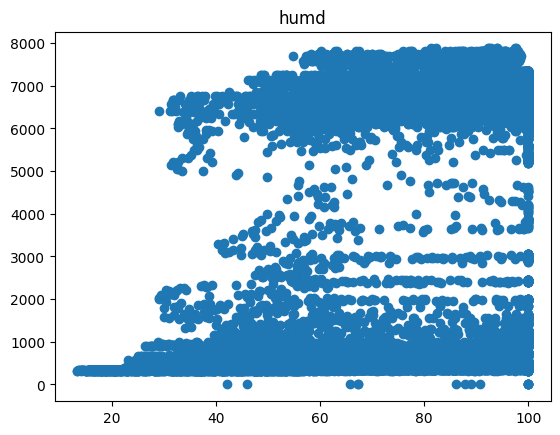

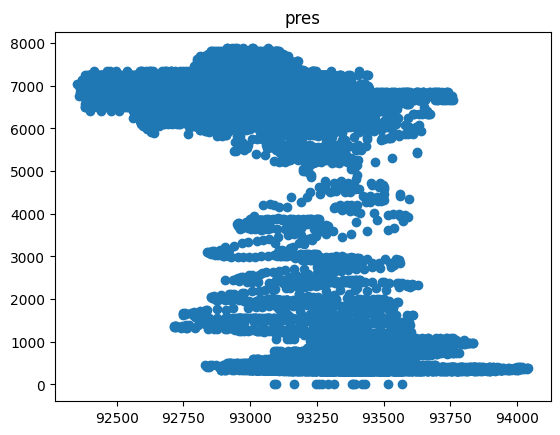

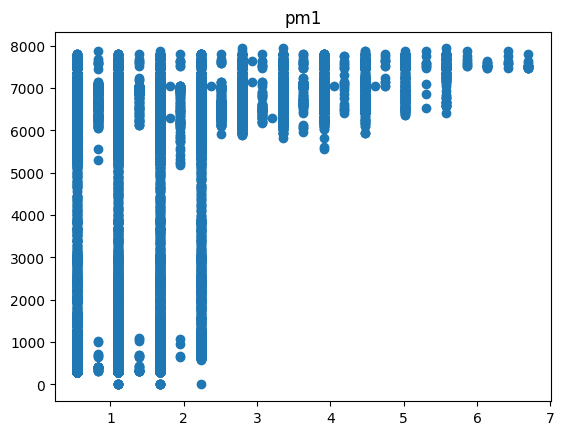

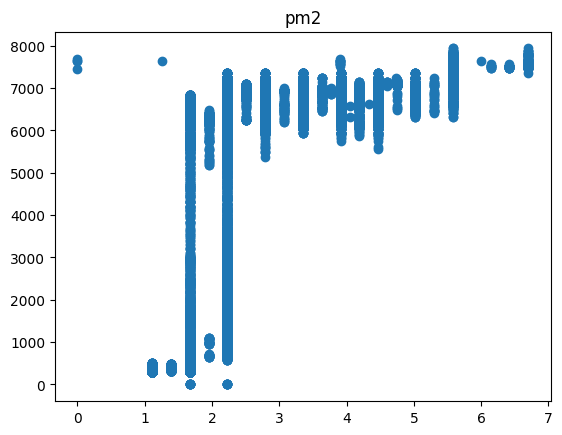

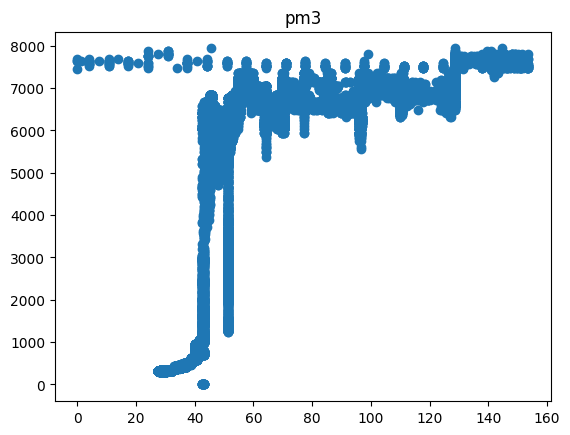

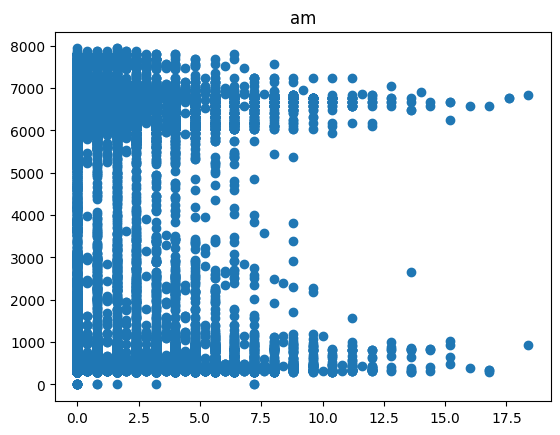

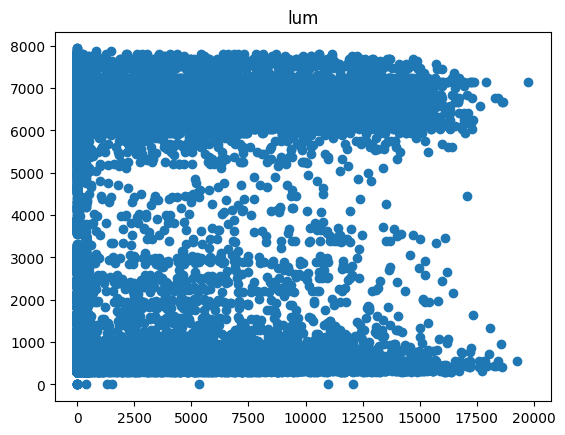

In [20]:
for i in data_comb.columns.drop('sm'):
  ypoints = data_comb['sm']
  plt.scatter(data_comb[i], ypoints)
  plt.title(i)
  plt.show()

**Giải thích:** Tương tự trên, cell này vẽ biểu đồ phân tán cho tập dữ liệu tổng hợp `data_comb`.

In [21]:
data_comb.isnull().sum()

st       13697
day          0
Month        0
year         0
hour         0
min          0
temp     12872
humd     12872
pres     12872
pm1          0
pm2          0
pm3          0
am           0
sm           0
lum          0
dtype: int64

In [22]:
data_comb.describe()

,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
count,19341.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,20166.000000,20166.000000,20166.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000
mean,26.852714,16.203644,8.086809,2022.162994,11.527998,6.505388,22.625972,78.329035,93154.619405,1.534521,2.476357,57.103645,1.383715,4122.373524,2795.742206
std,1.163759,9.026522,3.128060,0.369366,6.992460,3.456231,4.666760,24.007034,290.963485,0.976174,1.183368,26.138342,2.090352,3007.643883,4166.394793
min,24.040000,1.000000,1.000000,2022.000000,0.000000,1.000000,8.610000,13.320000,92352.450000,0.550000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.110000,8.000000,7.000000,2022.000000,5.000000,4.000000,20.000000,61.690000,92976.272500,0.550000,1.670000,36.880000,0.000000,474.000000,1.000000
50%,26.700000,17.000000,9.000000,2022.000000,12.000000,6.000000,21.430000,88.220000,93152.930000,1.110000,2.230000,48.330000,0.000000,6173.000000,47.500000
75%,27.390000,24.000000,10.000000,2022.000000,18.000000,9.000000,26.110000,100.000000,93350.997500,2.230000,3.350000,70.400000,2.400000,6757.000000,4991.375000
max,31.170000,31.000000,12.000000,2023.000000,23.000000,12.000000,36.880000,100.000000,94042.780000,6.700000,6.700000,153.660000,18.390000,7937.000000,19767.000000


# Model Runn Prep

In [23]:
from sklearn.preprocessing import StandardScaler        
from sklearn.model_selection import train_test_split 
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.ensemble import RandomForestRegressor


**Giải thích:** Cell này import các công cụ chuẩn bị và đánh giá mô hình từ `scikit-learn`:
- `StandardScaler`: chuẩn hóa giá trị các đặc trưng về cùng thang đo.
- `train_test_split`: chia dữ liệu thành tập huấn luyện và tập kiểm định.
- `mean_squared_error`, `mean_absolute_error`, `r2_score`: các chỉ số đánh giá sai số và độ phù hợp của mô hình hồi quy.
- `RandomForestRegressor`: mô hình hồi quy Rừng ngẫu nhiên.

In [24]:
data_comb.head()

,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
0,NaN,1,1,2023,0,1,17.03,92.56,93737.36,0.55,1.11,33.52,0.0,373.0,4.0
1,27.49,1,1,2023,0,5,16.72,94.43,93718.07,0.83,1.39,33.52,0.0,401.5,2.0
2,27.45,1,1,2023,0,9,NaN,NaN,NaN,1.11,1.67,33.52,0.0,431.0,1.0
3,NaN,1,1,2023,0,10,16.69,94.27,93694.30,1.67,1.11,33.52,0.0,373.0,3.0
4,27.40,1,1,2023,1,2,16.79,91.79,93670.49,0.55,1.39,33.52,0.0,401.5,2.0


In [25]:
data_comb.isnull().sum()

st       13697
day          0
Month        0
year         0
hour         0
min          0
temp     12872
humd     12872
pres     12872
pm1          0
pm2          0
pm3          0
am           0
sm           0
lum          0
dtype: int64

In [26]:
X=data_comb.drop('sm',axis=1)
y=data_comb['sm']

# Random Forest Regressor

In [27]:
def rfr_score_dataset(X_train, X_test, y_train, y_test):  
  forest = RandomForestRegressor(n_estimators=1000, 
                                criterion='squared_error', 
                                random_state=1, 
                                n_jobs=-1)
  forest.fit(X_train, y_train)
  y_test_pred = forest.predict(X_test)

  print("MSE : ",(mean_squared_error(y_test, y_test_pred)))
  print("MAE : ",mean_absolute_error(y_test, y_test_pred))
  print('score:', forest.score(X_test, y_test))
  print("R square : ",r2_score(y_test, y_test_pred, force_finite=False))

**Giải thích:** Cell này định nghĩa hàm `rfr_score_dataset` để huấn luyện và đánh giá nhanh mô hình `RandomForestRegressor`:
- Khởi tạo `RandomForestRegressor(n_estimators=1000, criterion='squared_error', random_state=1, n_jobs=-1)` với 1000 cây và chạy song song trên mọi nhân CPU.
- `forest.fit(X_train, y_train)` và `forest.predict(X_test)`: huấn luyện trên tập train và dự đoán trên tập test.
- In ra các chỉ số đánh giá gồm `MSE`, `MAE`, `score` và `R square`.

## RFR Imputation
 * use of Imputation method to clean Null Values

In [28]:
from sklearn.impute import SimpleImputer

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)


# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

print("MAE from Approach 2 (Imputation):")
print(rfr_score_dataset(imputed_X_train, imputed_X_valid, y_train, y_valid))

MAE from Approach 2 (Imputation):
MSE :  13670.032077918506
MAE :  39.40665995762712
score: 0.9984885173508142
R square :  0.9984885173508142
None


**Giải thích:** Cell này thử nghiệm phương pháp điền giá trị thiếu (Imputation) với `RandomForestRegressor`:
- `train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=32)`: chia dữ liệu theo tỉ lệ 80% huấn luyện, 20% kiểm định.
- `SimpleImputer()`: điền giá trị thiếu bằng trung bình cột (`fit_transform` trên train, `transform` trên valid).
- Gán lại tên cột cho `imputed_X_train` và `imputed_X_valid` vì đầu ra của `SimpleImputer` là mảng NumPy.
- Gọi `rfr_score_dataset(...)` để huấn luyện và in kết quả.

## RFR An Extension to Imputation

*   use of Imputation method to clean Null Values
*   And column is Added to classify Changed value



In [29]:
# Make copy to avoid changing original data (when imputing)
X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

print("MAE from Approach 3 (An Extension to Imputation):")
print(rfr_score_dataset(imputed_X_train_plus, imputed_X_valid_plus, y_train, y_valid))

MAE from Approach 3 (An Extension to Imputation):
MSE :  13536.707730677515
MAE :  38.09455917070218
score: 0.9985032588990724
R square :  0.9985032588990724
None


**Giải thích:** Cell này mở rộng phương pháp Imputation bằng cách thêm cột đánh dấu vị trí dữ liệu bị thiếu:
- Sao chép `X_train`, `X_valid` sang `X_train_plus`, `X_valid_plus` để không làm thay đổi dữ liệu gốc.
- Tìm các cột có giá trị null trong `X_train` và tạo thêm cột boolean `<tên_cột>_was_missing` cho cả tập train và valid.
- Dùng `SimpleImputer()` điền giá trị thiếu, khôi phục tên cột và gọi `rfr_score_dataset(...)` để đánh giá.

# RFR Pipeline

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score


**Giải thích:** Cell này import các lớp phục vụ xây dựng quy trình xử lý tự động và kiểm định mô hình:
- `Pipeline`: kết hợp tuần tự các bước tiền xử lý và mô hình học máy.
- `SimpleImputer`: xử lý dữ liệu thiếu.
- `StandardScaler`: chuẩn hóa đặc trưng.
- `cross_val_score`: đánh giá mô hình bằng phương pháp kiểm định chéo.

## RFR pipeline Imputation

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model 
my_pipeline.fit(imputed_X_train, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid, y_valid))

MAE: 39.27454517251816
0.9984864269117495


**Giải thích:** Cell này xây dựng và đánh giá `RandomForestRegressor` trong `Pipeline` với dữ liệu đã điền khuyết cơ bản:
- Chia dữ liệu 80/20 và xử lý giá trị thiếu bằng `SimpleImputer()`.
- Tạo `my_pipeline` gồm bước `preprocessor` (`SimpleImputer(strategy="mean")`) và bước `model` (`RandomForestRegressor(n_estimators=1000, random_state=32)`).
- Gọi `fit` để huấn luyện, `predict` để dự đoán trên tập valid, rồi tính và in `MAE` cùng `score`.

## RFR pipeline An Extension to Imputation

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Preprocessing of training data, fit model 
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

MAE: 38.0552784503632
0.9985156623058402


**Giải thích:** Cell này đánh giá `my_pipeline` trên dữ liệu có bổ sung cột đánh dấu giá trị thiếu (`*_was_missing`):
- Chia dữ liệu 80/20, tạo `X_train_plus`, `X_valid_plus`, thêm các cột `*_was_missing` và điền khuyết bằng `SimpleImputer()`.
- Huấn luyện lại `my_pipeline` trên `imputed_X_train_plus`, dự đoán trên `imputed_X_valid_plus` và in ra `MAE` cùng `score`.

# XG Boost


 ## XG Boost Imputation

In [34]:
from xgboost import XGBRegressor
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

my_model1 = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    early_stopping_rounds=5,
    n_jobs=4
)

my_model1.fit(
    imputed_X_train,
    y_train,
    eval_set=[(imputed_X_valid, y_valid)],
    verbose=False
)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

**Giải thích:** Cell này huấn luyện mô hình `XGBRegressor` trên dữ liệu đã điền giá trị thiếu:
- Import `XGBRegressor`, chia dữ liệu 80/20 và điền khuyết bằng `SimpleImputer()`.
- Khởi tạo `XGBRegressor(n_estimators=1000, learning_rate=0.05, early_stopping_rounds=5, n_jobs=4)` với tốc độ học 0.05 và cơ chế dừng sớm sau 5 vòng không cải thiện.
- Gọi `my_model1.fit(...)` kèm `eval_set` là tập valid để theo dõi quá trình dừng sớm.

In [35]:
preds = my_model1.predict(imputed_X_valid)
print(mean_absolute_error(y_valid, preds))
print(my_model1.score(imputed_X_valid, y_valid))

55.605976070099246
0.9980294787702525


## XG Boost An Extension to Imputation




In [37]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

my_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    early_stopping_rounds=5,
    n_jobs=4
)

my_model.fit(
    imputed_X_train_plus,
    y_train,
    eval_set=[(imputed_X_valid_plus, y_valid)],
    verbose=False
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

**Giải thích:** Cell này huấn luyện mô hình `XGBRegressor` trên dữ liệu mở rộng có thêm cột đánh dấu giá trị thiếu:
- Chia dữ liệu 80/20, tạo bản sao `X_train_plus`, `X_valid_plus`, bổ sung các cột `*_was_missing` và điền giá trị thiếu bằng `SimpleImputer()`.
- Khởi tạo `XGBRegressor` với cùng tham số và gọi `fit(...)` kèm `eval_set` trên tập valid.

In [38]:
preds = my_model.predict(imputed_X_valid_plus)
print(mean_absolute_error(y_valid, preds))
print(my_model.score(imputed_X_valid_plus, y_valid))

58.016799746644985
0.9979500797838204


# RESULT (comparing all result)

****
****
***Random Forest Regressor***
****
****
**RFR Imputation**
* MAE : 39.40665995762712
* score: 0.9984885173508142
*****
**RFR An Extension to Imputation**
* MAE :  38.09455917070218
* score: 0.9985032588990724
****
****
***RFR Pipeline***
****
****
**RFR Pipeline Imputation**
* MAE: 39.27454517251816
* score: 0.9984864269117495
****
**RFR Pipeline An Extension to Imputation**
* MAE: 38.0552784503632
* score: 0.9985156623058402
****
****
***XG Boost***
****
****
**XG Boost Imputation**
* MAE: 55.605976070099246
* score: 0.9980294787702525
****
**XG Boost An Extension to Imputation**
* MAE: 58.016799746644985
* score: 0.9979500797838204
****
****

# BEST MODEL

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model 
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

MAE: 38.0552784503632
0.9985156623058402


**Giải thích:** Cell này huấn luyện lại mô hình tốt nhất (**RFR Pipeline An Extension to Imputation**) trên tập dữ liệu có cột đánh dấu giá trị thiếu:
- Chia tập train/valid (80/20, `random_state=32`), tạo các cột `*_was_missing` và điền khuyết bằng `SimpleImputer()`.
- Đóng gói `SimpleImputer(strategy="mean")` và `RandomForestRegressor(n_estimators=1000, random_state=32)` trong `my_pipeline`.
- Gọi `fit` để huấn luyện, `predict` để lấy giá trị dự đoán `preds`, sau đó tính và in `MAE` cùng `score`.

# Đánh giá chi tiết và Trực quan hóa kết quả (Best Model)

Dựa trên kết quả so sánh giữa các mô hình thử nghiệm, mô hình đạt hiệu quả cao nhất là **RFR Pipeline An Extension to Imputation** (`RandomForestRegressor` với `n_estimators=1000`, `random_state=32`, kết hợp `SimpleImputer(strategy="mean")` và các cột đánh dấu giá trị thiếu `*_was_missing`).

**Kết quả đánh giá ghi nhận của mô hình tốt nhất trên tập kiểm định (validation):**
- **MAE**: `38.0552784503632`
- **Score (R^2)**: `0.9985156623058402`

Kết quả đánh giá Best Model (RFR Pipeline - Extension to Imputation):
MAE  : 38.055278
MSE  : 13424.529818
RMSE : 115.864273
R2   : 0.998516


,Thực tế (Actual),Dự đoán (Predicted),Sai số (Residual),Sai số tuyệt đối
0,6757.0,6783.0360,-26.0360,26.0360
1,6454.0,6623.7525,-169.7525,169.7525
2,499.0,498.3885,0.6115,0.6115
3,450.5,446.2325,4.2675,4.2675
4,371.0,370.1010,0.8990,0.8990
5,861.0,861.1360,-0.1360,0.1360
6,6623.0,6686.2040,-63.2040,63.2040
7,7047.5,7033.6110,13.8890,13.8890
8,7047.5,7035.3445,12.1555,12.1555
9,332.0,331.7880,0.2120,0.2120


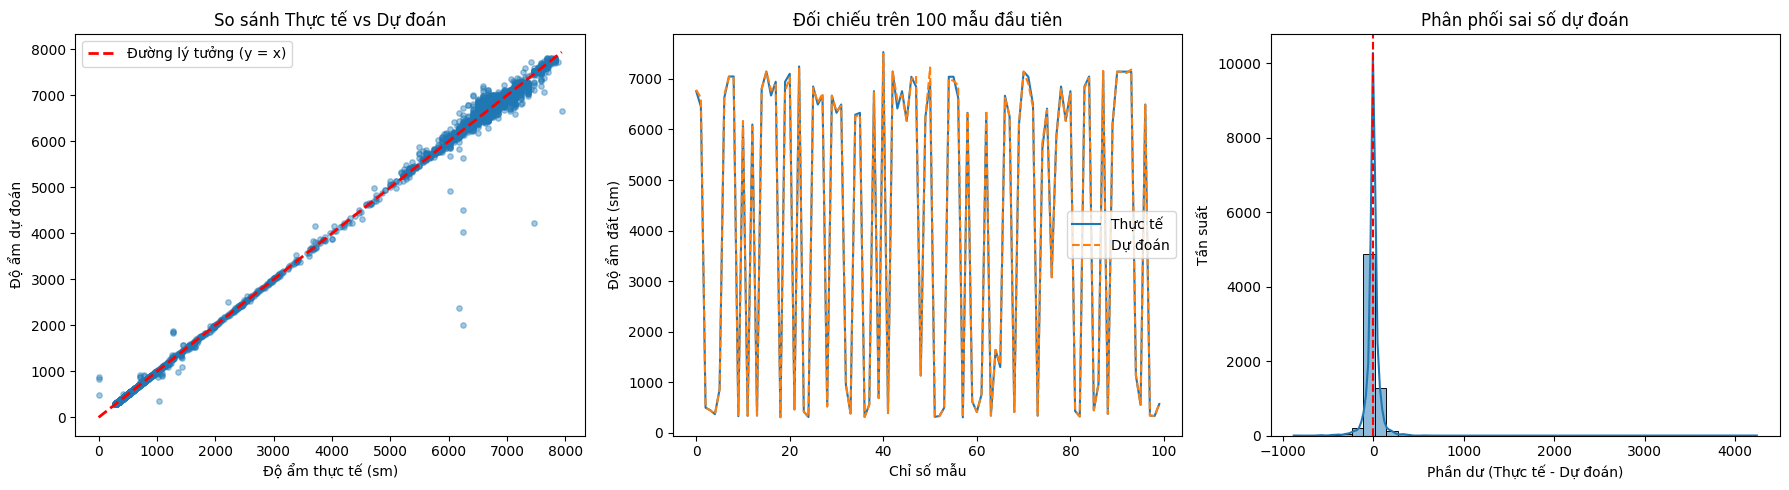

In [41]:
# Tính toán các chỉ số đánh giá chi tiết cho mô hình tốt nhất
mae_best = mean_absolute_error(y_valid, preds)
mse_best = mean_squared_error(y_valid, preds)
rmse_best = np.sqrt(mse_best)
r2_best = r2_score(y_valid, preds)

print("Kết quả đánh giá Best Model (RFR Pipeline - Extension to Imputation):")
print(f"MAE  : {mae_best:.6f}")
print(f"MSE  : {mse_best:.6f}")
print(f"RMSE : {rmse_best:.6f}")
print(f"R2   : {r2_best:.6f}")

# Bảng so sánh giá trị thực tế và giá trị dự đoán
comparison_df = pd.DataFrame({
    'Thực tế (Actual)': y_valid.values,
    'Dự đoán (Predicted)': preds,
    'Sai số (Residual)': y_valid.values - preds,
    'Sai số tuyệt đối': np.abs(y_valid.values - preds)
})
display(comparison_df.head(10))

# Trực quan hóa so sánh thực tế vs dự đoán và phân phối phần dư
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Biểu đồ phân tán Thực tế vs Dự đoán
axes[0].scatter(y_valid, preds, alpha=0.4, s=15)
min_val = min(y_valid.min(), preds.min())
max_val = max(y_valid.max(), preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Đường lý tưởng (y = x)')
axes[0].set_xlabel('Độ ẩm thực tế (sm)')
axes[0].set_ylabel('Độ ẩm dự đoán')
axes[0].set_title('So sánh Thực tế vs Dự đoán')
axes[0].legend()

# 2. Biểu đồ đường trên 100 mẫu đầu tiên của tập validation
sample_n = min(100, len(y_valid))
axes[1].plot(range(sample_n), y_valid.values[:sample_n], label='Thực tế', linewidth=1.5)
axes[1].plot(range(sample_n), preds[:sample_n], label='Dự đoán', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Chỉ số mẫu')
axes[1].set_ylabel('Độ ẩm đất (sm)')
axes[1].set_title(f'Đối chiếu trên {sample_n} mẫu đầu tiên')
axes[1].legend()

# 3. Phân phối phần dư (Residuals)
residuals = y_valid.values - preds
sns.histplot(residuals, bins=40, kde=True, ax=axes[2])
axes[2].axvline(0, color='r', linestyle='--', linewidth=1.5)
axes[2].set_xlabel('Phần dư (Thực tế - Dự đoán)')
axes[2].set_ylabel('Tần suất')
axes[2].set_title('Phân phối sai số dự đoán')

plt.tight_layout()
plt.show()

,Đặc trưng,Độ quan trọng,Tỉ lệ (%)
0,pm3,9.315014e-01,93.150138
1,day,4.182164e-02,4.182164
2,pm2,1.338093e-02,1.338093
3,st,4.306687e-03,0.430669
4,Month,4.162062e-03,0.416206
5,hour,1.195533e-03,0.119553
6,st_was_missing,8.679947e-04,0.086799
7,pm1,4.683614e-04,0.046836
8,pres,3.955684e-04,0.039557
9,humd_was_missing,3.597813e-04,0.035978


/tmp/ipykernel_50/4116876842.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


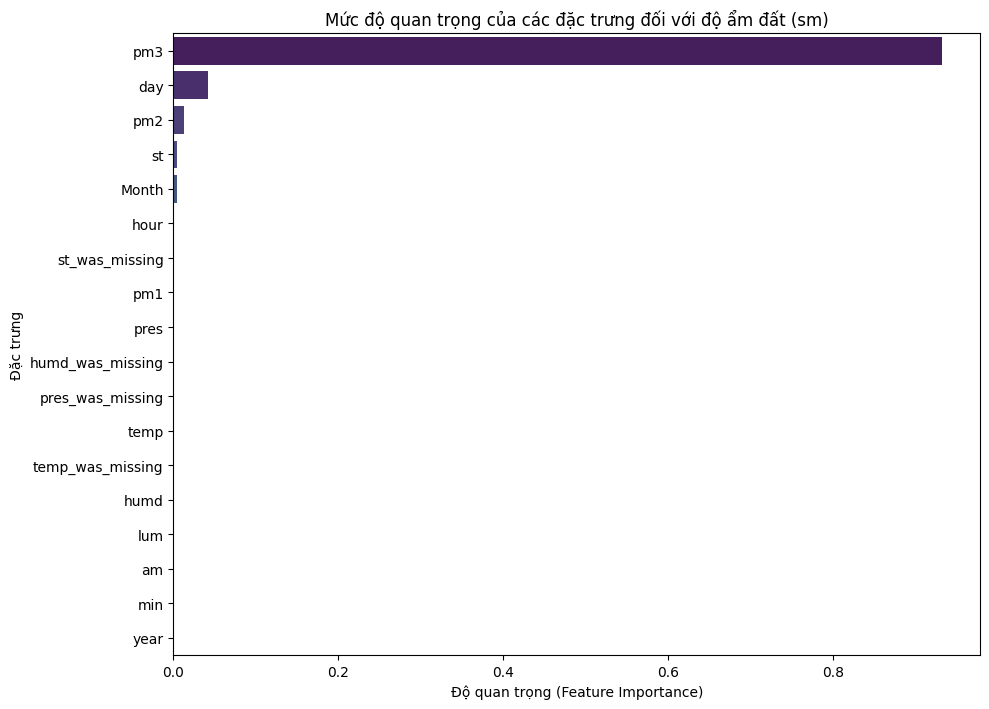

In [42]:
# Trích xuất độ quan trọng của từng đặc trưng từ mô hình RandomForestRegressor trong pipeline
rf_model = my_pipeline.named_steps['model']
feature_importance_df = pd.DataFrame({
    'Đặc trưng': imputed_X_valid_plus.columns,
    'Độ quan trọng': rf_model.feature_importances_
}).sort_values(by='Độ quan trọng', ascending=False).reset_index(drop=True)

feature_importance_df['Tỉ lệ (%)'] = feature_importance_df['Độ quan trọng'] * 100
display(feature_importance_df)

# Vẽ biểu đồ thanh ngang thể hiện mức độ quan trọng của từng đặc trưng
plt.figure(figsize=(10, max(5, len(feature_importance_df) * 0.4)))
sns.barplot(
    data=feature_importance_df,
    x='Độ quan trọng',
    y='Đặc trưng',
    palette='viridis'
)
plt.title('Mức độ quan trọng của các đặc trưng đối với độ ẩm đất (sm)')
plt.xlabel('Độ quan trọng (Feature Importance)')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()